# Assignment 1: Basic EDA

1. Read in the "Computers.csv" file. 
2. Explore the **target variable, "price"**. Look at a `histogram` and `boxplot` of it.
3. Then, produce `histograms` of the **'speed'** and **'ram'** variables. 
4. Feel free to further explore the dataset!

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
computers = pd.read_csv("../datasets/Computers.csv")

computers.head()

,price,speed,hd,ram,screen,cd,multi,premium,ads,trend
0,1499,25,80,4,14,no,no,yes,94,1
1,1795,33,85,2,14,no,no,yes,94,1
2,1595,25,170,4,15,no,no,yes,94,1
3,1849,25,170,8,14,no,no,no,94,1
4,3295,33,340,16,14,no,no,yes,94,1


In [3]:
computers.info()

<class 'pandas.DataFrame'>
RangeIndex: 6259 entries, 0 to 6258
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   price    6259 non-null   int64
 1   speed    6259 non-null   int64
 2   hd       6259 non-null   int64
 3   ram      6259 non-null   int64
 4   screen   6259 non-null   int64
 5   cd       6259 non-null   str  
 6   multi    6259 non-null   str  
 7   premium  6259 non-null   str  
 8   ads      6259 non-null   int64
 9   trend    6259 non-null   int64
dtypes: int64(7), str(3)
memory usage: 489.1 KB


In [4]:
computers.describe().T.round()

,count,mean,std,min,25%,50%,75%,max
price,6259.0,2220.0,581.0,949.0,1794.0,2144.0,2595.0,5399.0
speed,6259.0,52.0,21.0,25.0,33.0,50.0,66.0,100.0
hd,6259.0,417.0,259.0,80.0,214.0,340.0,528.0,2100.0
ram,6259.0,8.0,6.0,2.0,4.0,8.0,8.0,32.0
screen,6259.0,15.0,1.0,14.0,14.0,14.0,15.0,17.0
ads,6259.0,221.0,75.0,39.0,162.0,246.0,275.0,339.0
trend,6259.0,16.0,8.0,1.0,10.0,16.0,22.0,35.0


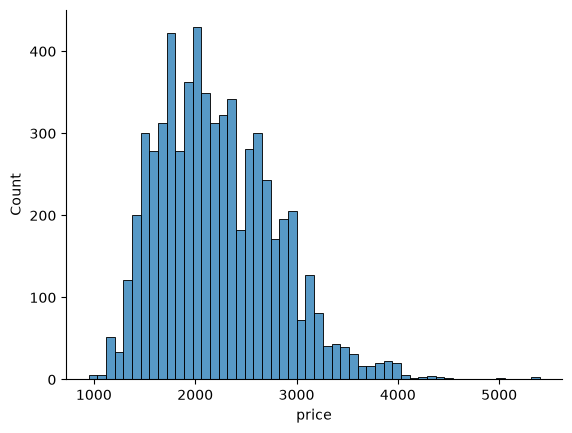

In [5]:
# 2.1. Histogram of Price
sns.histplot(x=computers.price)
sns.despine()

>The `mean` and `median` are close to 2100.
>
>The distribution of prices shows a right skewed plot

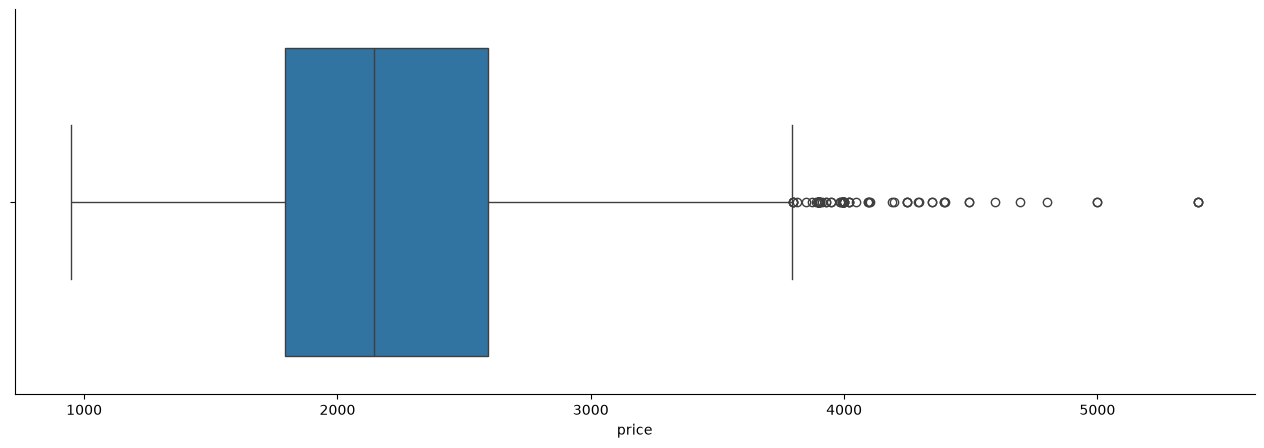

In [6]:
# 2.2 Boxplot of Price
plt.figure(figsize=(16, 5))
sns.boxplot(x=computers.price)
sns.despine()

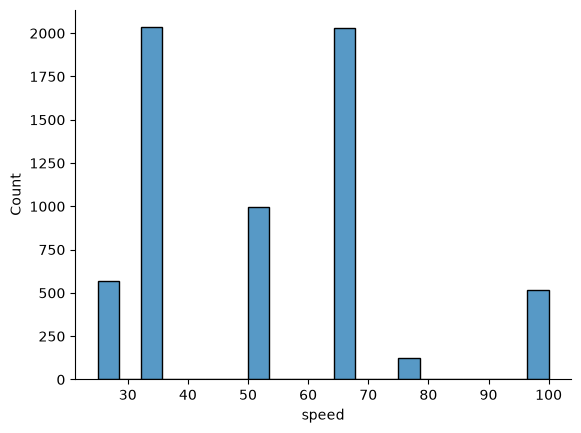

In [7]:
# 3.1. Histogram of the Feature Speed

sns.histplot(x=computers.speed)
sns.despine()

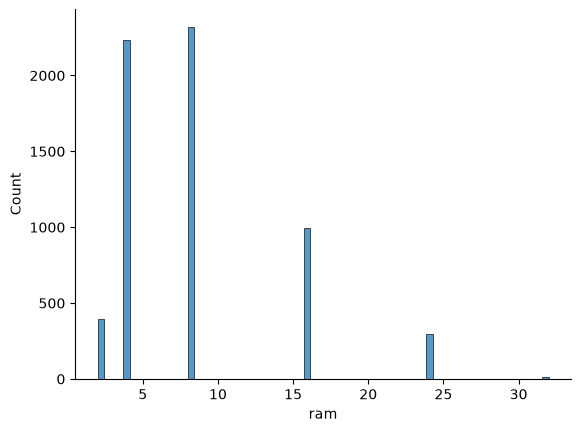

In [8]:
# 3.2. Histogram of the Feature RAM
sns.histplot(x=computers.ram)
sns.despine()

> The upper two plots (*speed and ram*) show us that both plots have no normal distribution behaviour.
>
> We'll need to check `speed` and `ram` later on Feature Engineering.

---

<br><br>

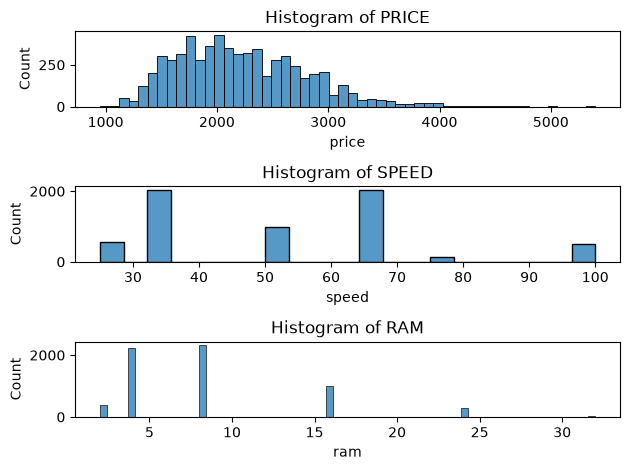

In [20]:
# Let's create a loop to reduce some time

columns = ['price', 'speed', 'ram']
data = computers

fig, ax = plt.subplots(len(columns), layout='tight')

for col, ax in zip(columns, ax.flat):
    sns.histplot(data=data, x=col, ax=ax)
    ax.set_title(f"Histogram of {col.upper()}")

## Assignment 2: Variable Relationships

1. Build a correlation matrix of numeric features and pass it into a heatmap
2. Build a pairplot of numeric features in the data. Hint: df.select_dtypes("number") selects numeric columns. Consider sampling with df.sample(1000) to speed this up if it takes too long.
3. Build an lmplot of ram vs. price. Does being a premium model (premium == 'yes') impact this relationship? 